In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99
from sklearn.cluster import KMeans

np.random.seed(1111)

In [2]:
kdd = fetch_kddcup99(subset=None, as_frame=True)
df = kdd.data.copy()

df = pd.get_dummies(df, columns=["protocol_type", "service", "flag"], dtype=float)
df = df.astype(float)
df = df.drop(columns=df.columns[df.min() == df.max()])
df = (df-df.min())/(df.max()-df.min())

D = df.to_numpy(dtype=np.float32)
n = D.shape[0]
d = D.shape[1]

print(f"Number of Rows (n) = {n}\nNumber of Columns (d) = {d}")

y = (kdd.target != b'normal.').to_numpy(dtype=float)

Number of Rows (n) = 494021
Number of Columns (d) = 116


In [3]:
k = 15
start = time.perf_counter()
km = KMeans(n_clusters=k, n_init=5, random_state=0)
km_D = km.fit(D)
end = time.perf_counter()

B = km_D.cluster_centers_
clusters_D = km_D.labels_

cost_db = 0
for i in range(0,n):
    b = B[clusters_D[i]]
    cost_db += np.sum((D[i] - b)**2)

time_y = end - start
print(f"cost(D, B) = {round(cost_db, 2)}")
print(f"Wall-clock time = {round(end-start, 2)} seconds")

cost(D, B) = 54003.69140625
Wall-clock time = 3.77 seconds


In [4]:
m = [5, 10, 15, 20, 25]
data = {}
for i in m:
    data[i] = []

for i in range(0,len(m)):
    print(f"For m = {m[i]}")
    for j in range(0,5):
        trial_list = []
        A = np.random.normal(0, 1/np.sqrt(m[i]), (m[i], d)).astype(np.float32)
        start = time.perf_counter()
        E = D@A.T
        km = KMeans(n_clusters=k, n_init=5, random_state=j)
        km_E = km.fit(E)
        end = time.perf_counter()
        const_time = end - start
        trial_list.append(const_time)
        
        lbl_E = km_E.labels_

        B2 = np.zeros((k, d))
        for x in range(0,k):
            cluster_pts = D[lbl_E == x]
            B2[x] = np.mean(cluster_pts, axis=0)

        sq_dists = np.zeros((n, k))
        for x in range(k):
            sq_dists[:,x] = np.sum((D - B2[x])**2, axis=1)
        min_dists = np.min(sq_dists, axis=1)
        cost = np.sum(min_dists, dtype=np.float64)
        trial_list.append(cost/cost_db)

        A_inv = np.linalg.pinv(A)
        centers_E = km_E.cluster_centers_
        B_inv = np.dot(centers_E, A_inv.T)

        sq_dists_inv = np.zeros((len(D), k))
        for x in range(k):
            sq_dists_inv[:, x] = np.sum((D - B_inv[x])**2, axis=1)
        min_dists_inv = np.min(sq_dists_inv, axis=1)
        cost_inv = np.sum(min_dists_inv, dtype=np.float64)
        trial_list.append(cost_inv/cost_db)
        
        data[m[i]].append(trial_list)
        print(f"Trial {j+1}:\nTime to compute E and run K-Means = {const_time:.4f} s | cost(D, B̂) = {cost:.4f} | Ratio (cost(D, B̂)/cost(D, B)) = {trial_list[1]:.4f} | Ratio (cost(D, B+)/cost(D, B)) = {trial_list[2]:.4f}")
    print('\n')

For m = 5
Trial 1:
Time to compute E and run K-Means = 1.2421 s | cost(D, B̂) = 62522.8802 | Ratio (cost(D, B̂)/cost(D, B)) = 1.1578 | Ratio (cost(D, B+)/cost(D, B)) = 80.3044
Trial 2:
Time to compute E and run K-Means = 1.4281 s | cost(D, B̂) = 68098.3550 | Ratio (cost(D, B̂)/cost(D, B)) = 1.2610 | Ratio (cost(D, B+)/cost(D, B)) = 79.6589
Trial 3:
Time to compute E and run K-Means = 1.1586 s | cost(D, B̂) = 65559.6900 | Ratio (cost(D, B̂)/cost(D, B)) = 1.2140 | Ratio (cost(D, B+)/cost(D, B)) = 79.9986
Trial 4:
Time to compute E and run K-Means = 1.1085 s | cost(D, B̂) = 61747.2727 | Ratio (cost(D, B̂)/cost(D, B)) = 1.1434 | Ratio (cost(D, B+)/cost(D, B)) = 79.8446
Trial 5:
Time to compute E and run K-Means = 1.2282 s | cost(D, B̂) = 74027.5424 | Ratio (cost(D, B̂)/cost(D, B)) = 1.3708 | Ratio (cost(D, B+)/cost(D, B)) = 79.3076


For m = 10
Trial 1:
Time to compute E and run K-Means = 1.2849 s | cost(D, B̂) = 64606.5984 | Ratio (cost(D, B̂)/cost(D, B)) = 1.1963 | Ratio (cost(D, B+)/cos

In [29]:
rows = []
for i in range(0,len(m)):
    trials = np.array(data[m[i]])
    rows.append({
        "m": m[i],
        "mean_ratio": trials[:,1].mean(),
        "min_ratio": trials[:,1].min(),
        "max_ratio": trials[:,1].max(),
        "mean_ratio_Binv": trials[:,2].mean()
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False,float_format="%.4f"))

 m  mean_ratio  min_ratio  max_ratio  mean_ratio_Binv
 5      1.1872     1.0213     1.3038          80.5507
10      1.0481     0.9980     1.1032          75.0099
15      1.0875     1.0146     1.1940          68.7426
20      1.0214     0.9676     1.0817          69.0554
25      1.0476     1.0216     1.0750          64.1719


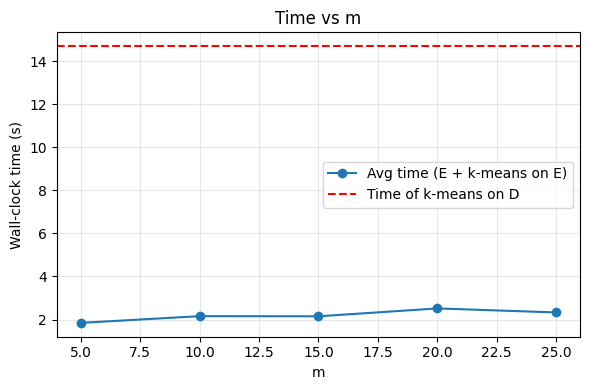

In [ ]:
plotting_data = []

for i in range(0, len(m)):
    avg = np.mean(np.array(data[m[i]])[:,0],axis=0)
    plotting_data.append(avg)

plt.figure(figsize=(6, 4))
plt.plot(m, plotting_data, 'o-', label='Mine time to compute E and run k-means on E')
plt.axhline(y=time_y, color='r', linestyle='--', label='Time to run k-means on D')
plt.xlabel('m')
plt.ylabel('Wall-clock time (secs)')
plt.title('Mean Time vs m')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
i_mask = np.random.randint(0, n, size=20000)
l_mask = np.random.randint(0, n, size=20000)

dist_D = np.sum((D[i_mask] - D[l_mask])**2, axis=1, dtype=np.float64)

i_mask = i_mask[dist_D > 0]
i_mask = i_mask[:10000]

l_mask = l_mask[dist_D > 0]
l_mask = l_mask[:10000]

dist_D = dist_D[dist_D > 0]
dist_D = dist_D[:10000]

cost_cd = 0
for i in range(0, k):
    pts = D[clusters_D == i]
    mean_pt = np.mean(pts, axis=0)
    cost_cd += np.sum((pts - mean_pt)**2, dtype=np.float64)

e_data = {}
for x in m:
    e_data[x] = [[],[]]

for i in range(0, len(m)):
    A = np.random.normal(0, 1/np.sqrt(m[i]), (m[i], d)).astype(np.float32)
    dist_E = np.sum(((D[i_mask] - D[l_mask])@A.T)**2, axis=1, dtype=np.float64)
    e_data[m[i]][0] = dist_E/dist_D

    for draw in range(0, 20):
        A = np.random.normal(0, 1/np.sqrt(m[i]), (m[i], d)).astype(np.float32)
        E = D @ A.T

        costE_cd = 0
        for j in range(0, k):
            pts = E[clusters_D == j]
            mean_pt = np.mean(pts, axis=0)
            costE_cd+= np.sum((pts - mean_pt)**2, dtype=np.float64)

        e_data[m[i]][1].append(costE_cd/cost_cd)

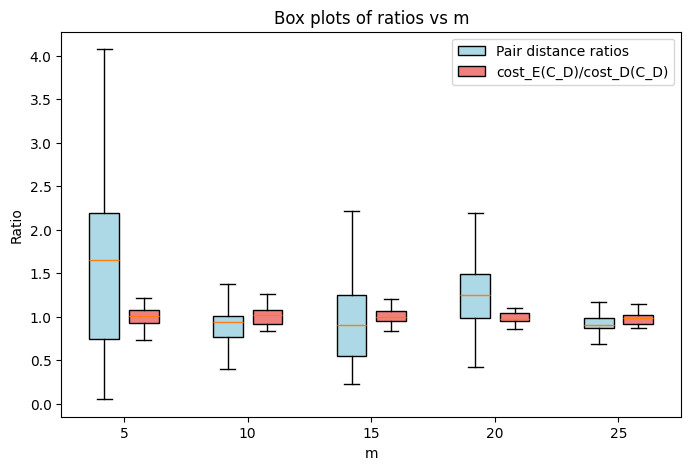

In [33]:
pairs = []
costs = []


for i in range(0, len(m)):
    pairs.append(e_data[m[i]][0])
    costs.append(e_data[m[i]][1])

plt.figure(figsize=(8, 5))

boxplot_pair = plt.boxplot(pairs, positions=np.array(m) - 0.8, widths=1.2, patch_artist=True, showfliers=False)
for i in boxplot_pair["boxes"]:
    i.set_facecolor("lightblue")

boxplot_cost = plt.boxplot(costs, positions=np.array(m) + 0.8, widths=1.2, patch_artist=True, showfliers=False)
for i in boxplot_cost["boxes"]:
    i.set_facecolor("lightcoral")

plt.xticks(m, m)
plt.xlabel("m")
plt.ylabel("Ratio")
plt.title("Box plots of ratios vs m")
plt.legend([boxplot_pair["boxes"][0], boxplot_cost["boxes"][0]], ["Pair distance ratios", "cost_E(C_D)/cost_D(C_D)"])
plt.show()